# DeLong's test: comparing correlated ROC AUCs

When several models are evaluated on the **same** test set their ROC AUCs are correlated, so comparing them as if they were independent is wrong, usually far too conservative. DeLong et al. (1988) derived a non-parametric estimate of the joint covariance of the AUCs, based on the Mann-Whitney statistic. MMU implements it with the fast $O(N \log N)$ algorithm of Sun & Xu (2014).

This notebook shows:

1. [Confidence intervals on the AUC](#Confidence-intervals-on-the-AUC) — `auc_confidence_interval`
2. [The DeLong covariance](#The-DeLong-covariance) — `delong_covariance`, and [why pairing matters](#Why-pairing-matters)
3. [Paired test of two models](#Paired-test-of-two-models) — `delong_test`
4. [Contrasts of multiple models](#Contrasts-of-multiple-models) — `delong_contrast_test`
5. [Edge cases](#Edge-cases)
6. [Calibration of the test and intervals](#Calibration-of-the-test-and-intervals)
7. [Performance and multi-threading](#Performance-and-multi-threading)

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

In [2]:
from sklearn.datasets import make_classification
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

In [3]:
import mmu
from mmu.viz.utils import _set_plot_style

In [4]:
%matplotlib inline
_ = _set_plot_style()

## Data and models

We train three classifiers and score them on a single, shared test set.

In [5]:
X, y = make_classification(
    n_samples=6000, n_features=20, n_informative=6, n_redundant=4, flip_y=0.08, class_sep=0.8, random_state=1949
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=3)

models = {
    "GBT": HistGradientBoostingClassifier(random_state=0),
    "LogReg": LogisticRegression(max_iter=1000),
    "NaiveBayes": GaussianNB(),
}
scores = np.column_stack([m.fit(X_train, y_train).predict_proba(X_test)[:, 1] for m in models.values()])
names = list(models)
print(f"test set: {y_test.size} observations, {y_test.sum()} positives; scores shape {scores.shape}")

test set: 1500 observations, 734 positives; scores shape (1500, 3)


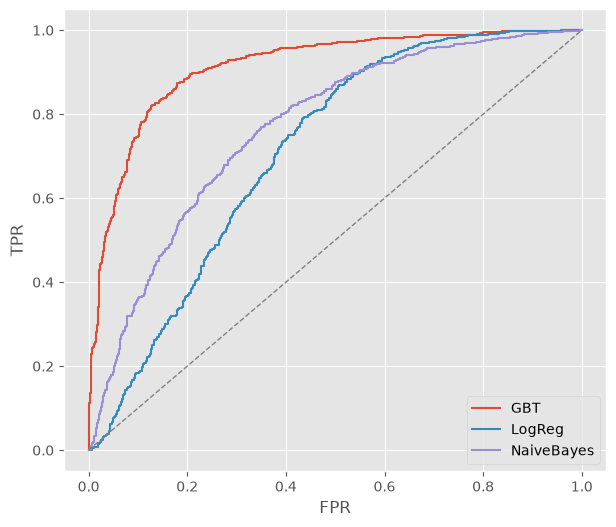

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, s in zip(names, scores.T):
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, label=name)
ax.plot([0, 1], [0, 1], c="grey", ls="--", lw=1)
ax.set_xlabel("FPR")
ax.set_ylabel("TPR")
ax.legend();

## Confidence intervals on the AUC

`auc_confidence_interval` returns the AUC, its DeLong standard error and a confidence interval for every model (columns of `scores`, or pass `obs_axis=1` for shape `(n_models, n_obs)`). A 1D `scores` array gives scalars.

- `method="wald"`: $\hat\theta \pm z_{1-\alpha/2}\,\widehat{se}$, clipped to $[0, 1]$; identical to `pROC::ci.auc(method="delong")`.
- `method="logit"`: the Wald interval on the logit scale, transformed back. Always inside $(0, 1)$ and better behaved for small samples or AUCs near 0 or 1.

In [7]:
wald = mmu.auc_confidence_interval(y_test, scores, alpha=0.05)
logit = mmu.auc_confidence_interval(y_test, scores, alpha=0.05, method="logit")
wald

AUCConfidenceInterval(auc=array([0.91246149, 0.71062741, 0.76771117]), lower=array([0.89786719, 0.68440513, 0.74392573]), upper=array([0.9270558 , 0.73684969, 0.79149661]), std_err=array([0.00744621, 0.01337896, 0.01213565]))

In [8]:
pd.DataFrame(
    {
        "AUC": wald.auc,
        "std err": wald.std_err,
        "wald lower": wald.lower,
        "wald upper": wald.upper,
        "logit lower": logit.lower,
        "logit upper": logit.upper,
    },
    index=names,
).round(4)

,AUC,std err,wald lower,wald upper,logit lower,logit upper
GBT,0.9125,0.0074,0.8979,0.9271,0.8967,0.9260
LogReg,0.7106,0.0134,0.6844,0.7368,0.6837,0.7361
NaiveBayes,0.7677,0.0121,0.7439,0.7915,0.7431,0.7906


In [9]:
# A single model returns scalars
mmu.auc_confidence_interval(y_test, scores[:, 0], alpha=0.1, method="logit")

AUCConfidenceInterval(auc=0.9124614935864134, lower=0.8994139136737632, upper=0.9239596884612752, std_err=0.00744621210640432)

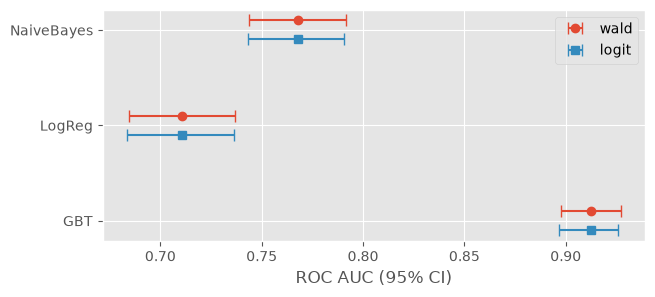

In [10]:
fig, ax = plt.subplots(figsize=(7, 3))
pos = np.arange(len(names))
ax.errorbar(wald.auc, pos + 0.1, xerr=[wald.auc - wald.lower, wald.upper - wald.auc], fmt="o", capsize=4, label="wald")
ax.errorbar(logit.auc, pos - 0.1, xerr=[logit.auc - logit.lower, logit.upper - logit.auc], fmt="s", capsize=4, label="logit")
ax.set_yticks(pos, names)
ax.set_xlabel("ROC AUC (95% CI)")
ax.legend();

These intervals describe each AUC on its own. To compare models evaluated on the same observations we also need the covariance between their AUC estimates.

## The DeLong covariance

`delong_covariance` returns the AUCs and their $k \times k$ covariance matrix

$$S = \frac{1}{m} S_{10} + \frac{1}{n} S_{01},$$

where $S_{10}$ and $S_{01}$ are the covariances of the structural components over the $m$ positives and $n$ negatives.

In [11]:
aucs, cov = mmu.delong_covariance(y_test, scores)
sd = np.sqrt(np.diag(cov))
corr = cov / np.outer(sd, sd)
pd.DataFrame(corr, index=names, columns=names).round(3)

,GBT,LogReg,NaiveBayes
GBT,1.000,0.401,0.518
LogReg,0.401,1.000,0.692
NaiveBayes,0.518,0.692,1.000


The AUC estimates are positively correlated, because the models make similar mistakes on the same observations. The variance of a difference is $\mathrm{Var}(\hat\theta_1) + \mathrm{Var}(\hat\theta_2) - 2\,\mathrm{Cov}(\hat\theta_1, \hat\theta_2)$, so ignoring the covariance overstates the uncertainty of the difference:

In [12]:
diff = aucs[0] - aucs[1]
se_unpaired = np.sqrt(cov[0, 0] + cov[1, 1])
se_paired = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
print(f"AUC difference GBT - LogReg: {diff:.4f}")
print(f"std err ignoring correlation: {se_unpaired:.4f} -> z = {diff / se_unpaired:.2f}")
print(f"std err DeLong (paired):      {se_paired:.4f} -> z = {diff / se_paired:.2f}")

AUC difference GBT - LogReg: 0.2018
std err ignoring correlation: 0.0153 -> z = 13.18
std err DeLong (paired):      0.0124 -> z = 16.24


### Why pairing matters

The difference above is large either way. It matters most for models that are close and highly correlated, e.g. a model and a slightly modified version of it. Below, two simulated models share most of their noise: their confidence intervals overlap substantially and an unpaired comparison finds nothing, while the paired DeLong test clearly detects the difference.

In [13]:
rng = np.random.default_rng(1)
n_obs = 1000
y_pair = rng.binomial(1, 0.3, n_obs)
shared = rng.normal(size=n_obs)
model_a = 1.0 * y_pair + shared + rng.normal(scale=0.3, size=n_obs)
model_b = 0.9 * y_pair + shared + rng.normal(scale=0.3, size=n_obs)
pair_scores = np.column_stack([model_a, model_b])

ci_pair = mmu.auc_confidence_interval(y_pair, pair_scores)
aucs_pair, cov_pair = mmu.delong_covariance(y_pair, pair_scores)
for name, auc, lo, hi in zip(["model A", "model B"], ci_pair.auc, ci_pair.lower, ci_pair.upper):
    print(f"{name}: AUC = {auc:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")
print(f"correlation of the AUC estimates: {cov_pair[0, 1] / np.sqrt(cov_pair[0, 0] * cov_pair[1, 1]):.3f}")

z_unpaired = (aucs_pair[0] - aucs_pair[1]) / np.sqrt(cov_pair[0, 0] + cov_pair[1, 1])
print(f"unpaired: z = {z_unpaired:.2f}, p = {2 * norm.sf(abs(z_unpaired)):.3f}")
paired = mmu.delong_test(y_pair, model_a, model_b)
print(f"DeLong:   z = {paired.z:.2f}, p = {paired.p_value:.2g}")

model A: AUC = 0.7627  95% CI [0.7315, 0.7939]
model B: AUC = 0.7365  95% CI [0.7039, 0.7691]
correlation of the AUC estimates: 0.900
unpaired: z = 1.14, p = 0.255
DeLong:   z = 3.58, p = 0.00034


## Paired test of two models

`delong_test` tests $H_0: \theta_1 = \theta_2$ and returns a `DeLongTestResult` named tuple. Internally the variance is computed from the differenced structural components, not as the difference above, which avoids catastrophic cancellation when models are very similar.

In [14]:
res = mmu.delong_test(y_test, scores[:, 0], scores[:, 1])
res

DeLongTestResult(auc1=0.9124614935864134, auc2=0.710627414432168, difference=0.20183407915424534, variance=0.00015454637314962113, z=16.235478345771366, p_value=2.8303298879941233e-59)

In [15]:
# named tuple: attribute access and unpacking both work
auc1, auc2, difference, variance, z, p_value = res
print(f"z = {res.z:.3f}, p = {res.p_value:.2e}")

z = 16.235, p = 2.83e-59


### One-sided alternatives

`alternative="greater"` tests $H_1: \theta_1 > \theta_2$, `"less"` tests $H_1: \theta_1 < \theta_2$. The statistic is the same, only the p-value changes.

In [16]:
for alternative in ("two-sided", "greater", "less"):
    r = mmu.delong_test(y_test, scores[:, 1], scores[:, 2], alternative=alternative)
    print(f"LogReg vs NaiveBayes  {alternative:>9}: z = {r.z:6.3f}  p = {r.p_value:.3g}")

LogReg vs NaiveBayes  two-sided: z = -5.661  p = 1.5e-08
LogReg vs NaiveBayes    greater: z = -5.661  p = 1
LogReg vs NaiveBayes       less: z = -5.661  p = 7.51e-09


## Contrasts of multiple models

`delong_contrast_test` tests $H_0: L\theta = 0$ for a contrast matrix $L$ of shape `(c, k)`:

- one row ($c = 1$): $z$-test, one-sided alternatives allowed;
- multiple rows: $\chi^2 = (L\hat\theta)^\top (L S L^\top)^{+} (L\hat\theta)$ with degrees of freedom equal to the rank of $L S L^\top$.

### Are all AUCs equal?

Without a contrast the default tests whether all $k$ AUCs are equal, using the $k-1$ rows $\theta_1 - \theta_r$.

In [17]:
res = mmu.delong_contrast_test(y_test, scores)
print(f"chi2 = {res.statistic:.2f}, df = {res.df}, p = {res.p_value:.2e}")
res.estimate, res.covariance

chi2 = 286.43, df = 2, p = 6.35e-63


(array([0.20183408, 0.14475032]),
 array([[1.54546373e-04, 8.09652471e-05],
        [8.09652471e-05, 1.09055293e-04]]))

### Custom contrasts

Is the GBT better than the average of the other two models?

In [18]:
res = mmu.delong_contrast_test(y_test, scores, contrast=[1.0, -0.5, -0.5], alternative="greater")
print(f"estimate = {res.estimate[0]:.4f}, z = {res.statistic:.2f}, p = {res.p_value:.2e}")

estimate = 0.1733, z = 16.80, p = 1.19e-63


A single-row contrast reproduces `delong_test` exactly:

In [19]:
pair = mmu.delong_contrast_test(y_test, scores, contrast=[0.0, 1.0, -1.0])
direct = mmu.delong_test(y_test, scores[:, 1], scores[:, 2])
print(f"contrast: z = {pair.statistic:.10f}, p = {pair.p_value:.10f}")
print(f"direct:   z = {direct.z:.10f}, p = {direct.p_value:.10f}")

contrast: z = -5.6612669836, p = 0.0000000150
direct:   z = -5.6612669836, p = 0.0000000150


### All pairwise comparisons

Pairwise tests from the same covariance. Multiple comparisons are your responsibility; here a Holm correction is applied.

In [20]:
rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        r = mmu.delong_test(y_test, scores[:, i], scores[:, j])
        rows.append({"model 1": names[i], "model 2": names[j], "difference": r.difference, "z": r.z, "p": r.p_value})
pairwise = pd.DataFrame(rows)

order = np.argsort(pairwise["p"].to_numpy())
holm = np.empty(len(order))
running = 0.0
for rank, idx in enumerate(order):
    running = max(running, (len(order) - rank) * pairwise["p"].iloc[idx])
    holm[idx] = min(running, 1.0)
pairwise["p (Holm)"] = holm
pairwise.round(4).assign(p=pairwise["p"].map("{:.2e}".format), **{"p (Holm)": pairwise["p (Holm)"].map("{:.2e}".format)})

,model 1,model 2,difference,z,p,p (Holm)
0,GBT,LogReg,0.2018,16.2355,2.83e-59,8.49e-59
1,GBT,NaiveBayes,0.1448,13.8611,1.09e-43,2.18e-43
2,LogReg,NaiveBayes,-0.0571,-5.6613,1.50e-08,1.50e-08


### Rank-deficient contrasts

Linearly dependent rows are handled through the pseudo-inverse: the degrees of freedom equal the rank, so redundant rows don't inflate the test.

In [21]:
res = mmu.delong_contrast_test(y_test, scores[:, :2], contrast=[[1.0, -1.0], [2.0, -2.0]])
z = mmu.delong_test(y_test, scores[:, 0], scores[:, 1]).z
print(f"df = {res.df}, chi2 = {res.statistic:.4f}, z**2 = {z**2:.4f}")

df = 1, chi2 = 263.5908, z**2 = 263.5908


## Edge cases

**Identical models** have zero difference and zero variance: $z = 0$, $p = 1$.

In [22]:
mmu.delong_test(y_test, scores[:, 0], scores[:, 0])

DeLongTestResult(auc1=0.9124614935864134, auc2=0.9124614935864134, difference=0.0, variance=0.0, z=0.0, p_value=1.0)

**Zero variance with a non-zero difference**, e.g. a perfect classifier against a constant one, makes the test undefined. MMU returns `NaN` and issues a `RuntimeWarning` instead of an infinite $z$ and $p = 0$.

In [23]:
y_small = np.array([0, 0, 0, 1, 1, 1])
perfect = y_small.astype(float)
constant = np.full(6, 0.5)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = mmu.delong_test(y_small, perfect, constant)
print(res)
print(caught[0].category.__name__, caught[0].message)

DeLongTestResult(auc1=1.0, auc2=0.5, difference=0.5, variance=0.0, z=nan, p_value=nan)
RuntimeWarning DeLong variance estimate is zero while the AUCs differ; the test is undefined, returning NaN.


**Ties** in scores count as one half, as in the Mann-Whitney statistic, so discrete scores are fine. A constant model has AUC 0.5 and zero variance. Each class needs at least two observations, and scores must be finite.

In [24]:
discrete = np.round(scores * 4) / 4  # five score levels
aucs_d, cov_d = mmu.delong_covariance(y_test, np.column_stack([discrete, np.zeros(y_test.size)]))
print("AUCs:", aucs_d.round(4))
print("variance constant model:", cov_d[-1, -1])

AUCs: [0.9052 0.6826 0.7601 0.5   ]
variance constant model: 0.0


In [25]:
with_nan = scores[:, 0].copy()
with_nan[0] = np.nan
try:
    mmu.delong_test(y_test, with_nan, scores[:, 1])
except ValueError as err:
    print("ValueError:", err)

ValueError: Non-finite values encountered


## Calibration of the test and intervals

### p-values under the null hypothesis

Two correlated models with the **same** true AUC: the p-values should be uniform, so 5% of tests reject at $\alpha = 0.05$.

rejection rate at alpha=0.05: 0.046


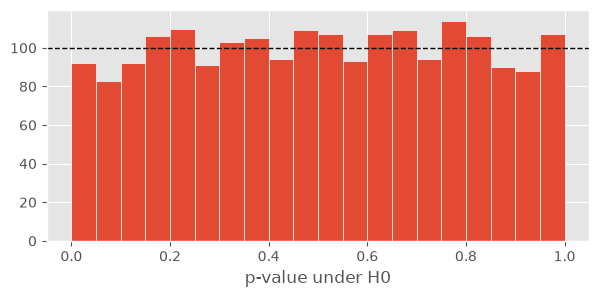

In [26]:
rng = np.random.default_rng(2024)
n_reps, n_obs = 2000, 400
p_values = np.empty(n_reps)
for i in range(n_reps):
    y_sim = rng.binomial(1, 0.35, n_obs)
    shared = rng.normal(size=n_obs)
    s1 = 0.8 * y_sim + shared + rng.normal(scale=0.7, size=n_obs)
    s2 = 0.8 * y_sim + shared + rng.normal(scale=0.7, size=n_obs)
    p_values[i] = mmu.delong_test(y_sim, s1, s2, n_threads=1).p_value

print(f"rejection rate at alpha=0.05: {(p_values < 0.05).mean():.3f}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(p_values, bins=20, range=(0, 1), edgecolor="white")
ax.axhline(n_reps / 20, c="k", ls="--", lw=1)
ax.set_xlabel("p-value under H0");

### Coverage of the confidence intervals

Binormal model with unit variances where the true AUC is $\Phi(\delta/\sqrt{2})$. With few observations and a high AUC the Wald interval under-covers; the logit interval stays close to the nominal 95%.

In [27]:
rng = np.random.default_rng(7)
n_reps = 2000
rows = []
for n_pos, n_neg in [(30, 45), (60, 90), (300, 450)]:
    y_sim = np.r_[np.ones(n_pos), np.zeros(n_neg)].astype(int)
    for delta in (1.0, 2.5):
        true_auc = norm.cdf(delta / np.sqrt(2))
        sims = np.column_stack(
            [np.r_[rng.normal(delta, 1, n_pos), rng.normal(0, 1, n_neg)] for _ in range(n_reps)]
        )
        row = {"n_pos": n_pos, "n_neg": n_neg, "true AUC": round(true_auc, 3)}
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)  # rare perfect separation
            for method in ("wald", "logit"):
                ci = mmu.auc_confidence_interval(y_sim, sims, method=method)
                row[method] = np.mean((ci.lower <= true_auc) & (true_auc <= ci.upper))
        rows.append(row)
pd.DataFrame(rows)

,n_pos,n_neg,true AUC,wald,logit
0,30,45,0.760,0.9355,0.9580
1,30,45,0.961,0.8760,0.9420
2,60,90,0.760,0.9570,0.9605
3,60,90,0.961,0.9055,0.9475
4,300,450,0.760,0.9500,0.9520
5,300,450,0.961,0.9455,0.9530


## Performance and multi-threading

Each model needs a single sort, $O(N \log N)$, and the covariance is $O(k^2 N)$. The GIL is released, and with OpenMP the models and covariance entries are processed in parallel via `n_threads`. Results do not depend on the number of threads.

`delong_test` only has two models, so more than two threads doesn't help.

In [28]:
rng = np.random.default_rng(0)
n_obs, n_models = 1_000_000, 10
y_big = rng.binomial(1, 0.4, n_obs)
scores_big = y_big[:, None] + rng.normal(size=(n_obs, n_models))

def best_of(fn, reps=3):
    times = []
    for _ in range(reps):
        start = time.perf_counter()
        out = fn()
        times.append(time.perf_counter() - start)
    return min(times), out

t, res_test = best_of(lambda: mmu.delong_test(y_big, scores_big[:, 0], scores_big[:, 1]))
print(f"delong_test, {n_obs:,} observations: {1e3 * t:.0f} ms")

reference = None
for n_threads in (1, 2, 4, 8):
    t, (aucs_big, cov_big) = best_of(lambda: mmu.delong_covariance(y_big, scores_big, n_threads=n_threads))
    reference = cov_big if reference is None else reference
    same = np.array_equal(cov_big, reference)
    print(f"delong_covariance, {n_models} models, n_threads={n_threads}: {1e3 * t:5.0f} ms  identical: {same}")

delong_test, 1,000,000 observations: 110 ms
delong_covariance, 10 models, n_threads=1:  1080 ms  identical: True
delong_covariance, 10 models, n_threads=2:   543 ms  identical: True
delong_covariance, 10 models, n_threads=4:   332 ms  identical: True
delong_covariance, 10 models, n_threads=8:   230 ms  identical: True


## References

- E. R. DeLong, D. M. DeLong and D. L. Clarke-Pearson, "Comparing the Areas under Two or More Correlated Receiver Operating Characteristic Curves: A Nonparametric Approach", *Biometrics*, 44(3), 837–845, 1988.
- X. Sun and W. Xu, "Fast Implementation of DeLong's Algorithm for Comparing the Areas Under Correlated Receiver Operating Characteristic Curves", *IEEE Signal Processing Letters*, 21(11), 1389–1393, 2014.
- X. Robin et al., "pROC: an open-source package for R and S+ to analyze and compare ROC curves", *BMC Bioinformatics*, 12, 77, 2011.